# Week 9 · Topic 2 — bcrypt in Python

**Mohammed Mohammed Alhaji** · CST1510 · 26 November 2026

**Box we are building: PROCESS, made safe, for real**

Two functions, and the one design choice worth understanding: bcrypt is slow
on purpose.

> **Already know this?** Skip to the *Topic 2 Challenge*.

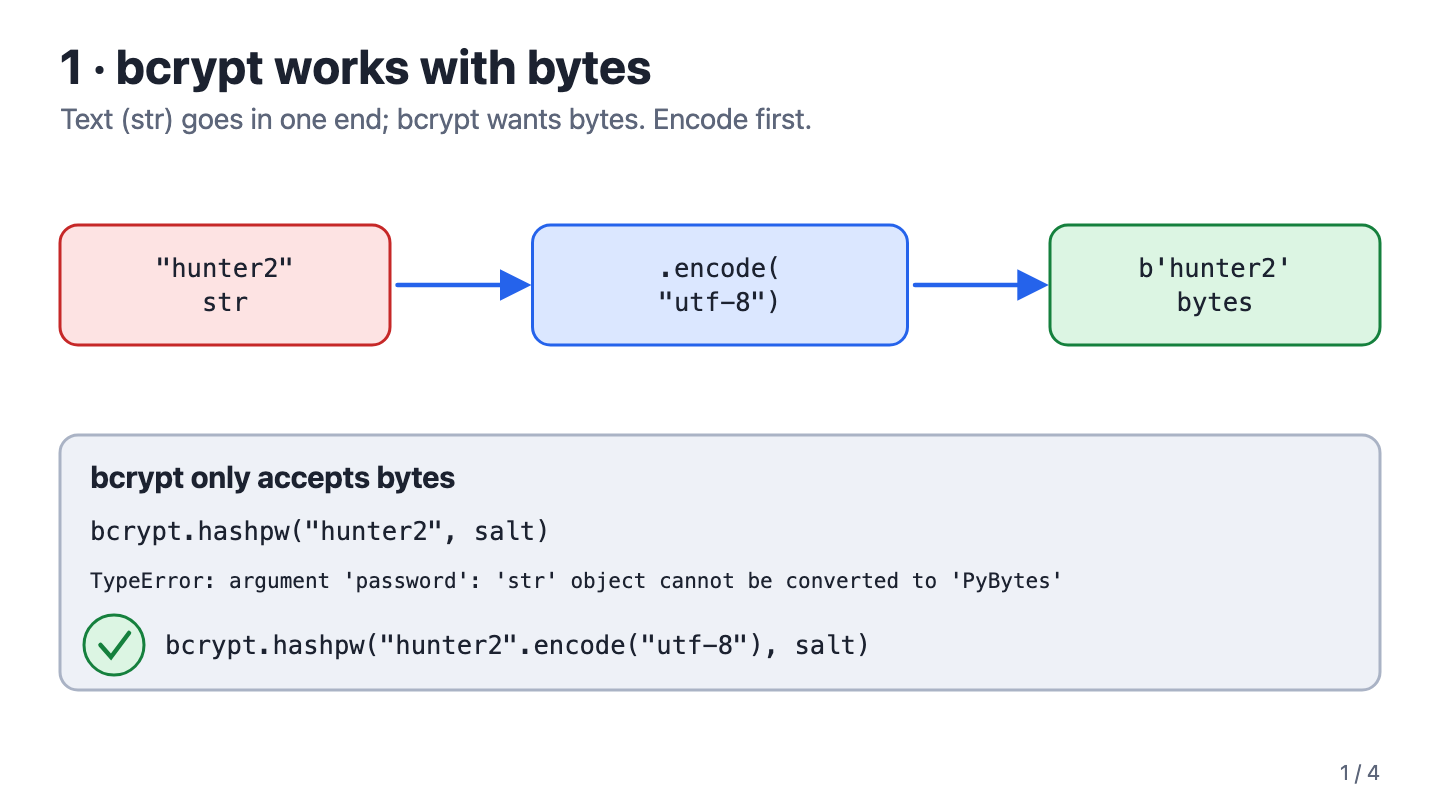

---
## 1. bcrypt works with bytes — encode first

In [1]:
import bcrypt

password = "correct-horse-battery-staple"
password_bytes = password.encode("utf-8")

### Your turn
Encode a password of your own choosing to bytes.

In [2]:
# This is a public practice value, not a real account password.
my_password = "practice-river-stone-26"
my_password_bytes = my_password.encode("utf-8")
print(my_password_bytes)
print(type(my_password_bytes))
assert isinstance(my_password_bytes, bytes)


b'practice-river-stone-26'
<class 'bytes'>


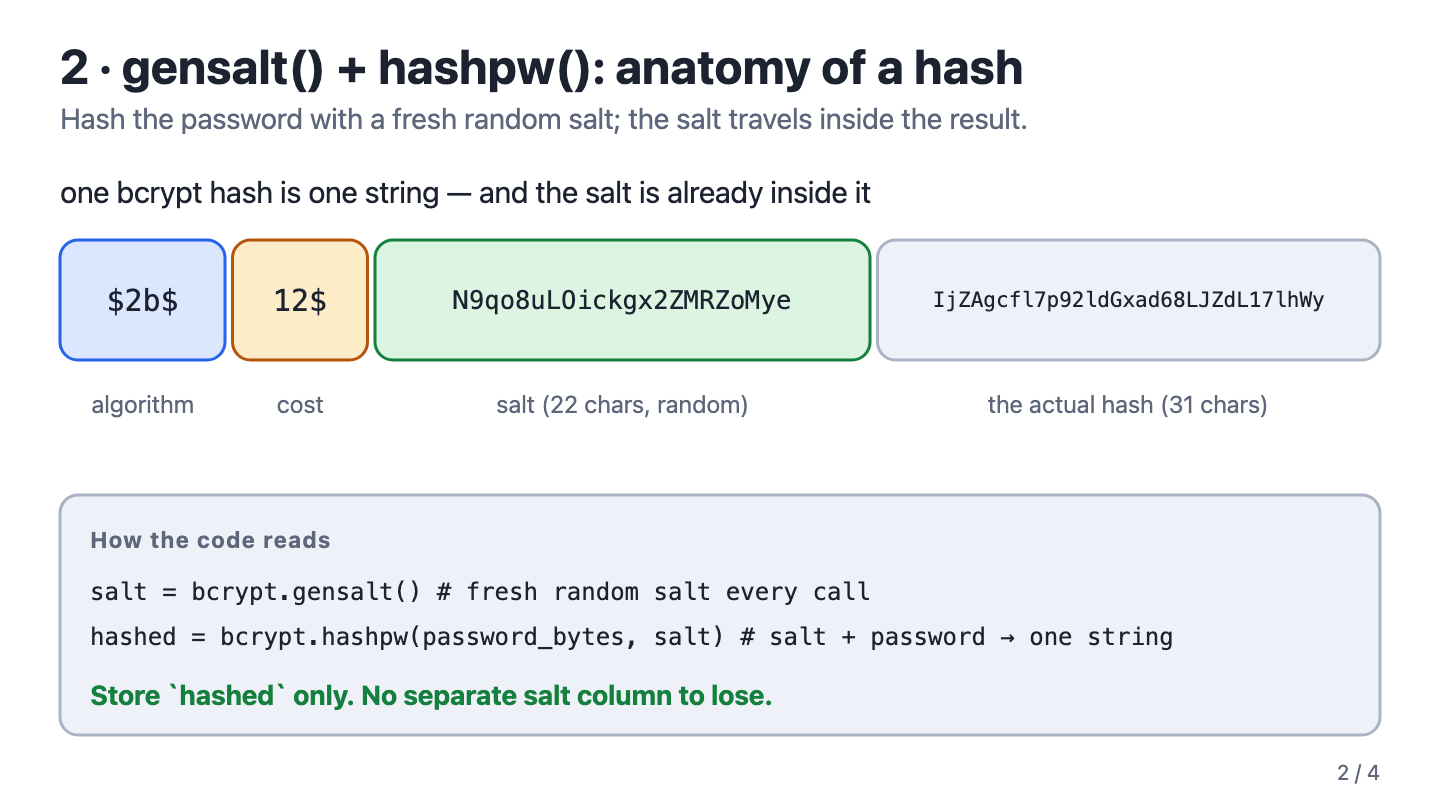

---
## 2. `gensalt()` + `hashpw()` — generating a hash

The salt is generated fresh, at random, and embedded inside the hash itself —
you never store it separately.

In [3]:
salt = bcrypt.gensalt()
hashed = bcrypt.hashpw(password_bytes, salt)
print(hashed.decode("utf-8"))
print(len(hashed))    # always 60 characters

$2b$12$dyCv9zZXDYENQsVX5.XblOosVzZxM4ErtstwZefB1mgN01L0ZkqIG
60


### Your turn
Hash your own encoded password from section 1 and print the result.

In [4]:
my_hash = bcrypt.hashpw(my_password_bytes, bcrypt.gensalt())
print(my_hash.decode("utf-8"))
print("Hash length:", len(my_hash))
assert len(my_hash) == 60


$2b$12$xZzCshVxqiwnD1bgGQGMtOqBlnONlKO2aOyaszCEv4ur9TJmTylp2
Hash length: 60


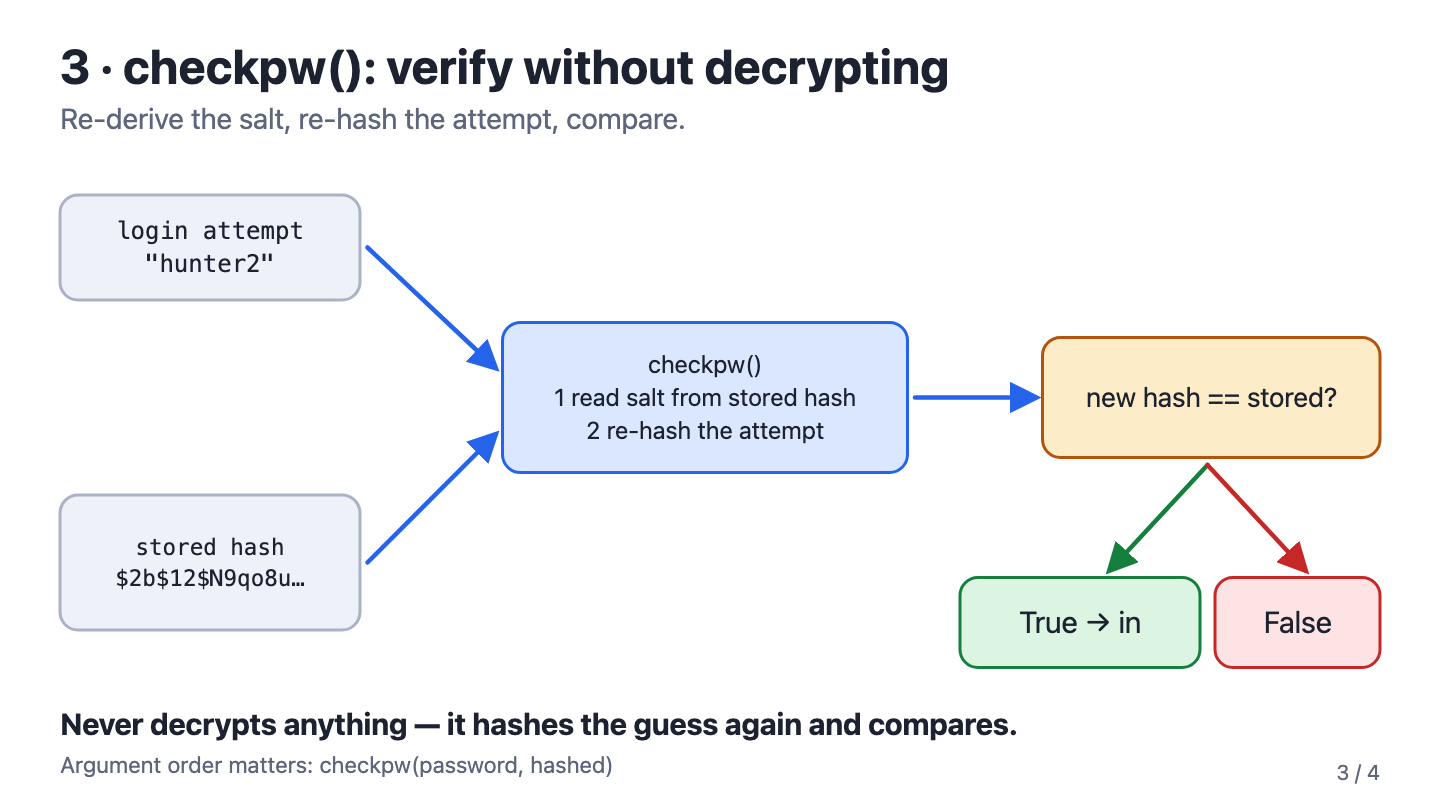

---
## 3. `checkpw()` — verifying, without ever decrypting

Re-derives the salt from the stored hash, re-hashes the candidate, and
compares.

In [5]:
print(bcrypt.checkpw(b"correct-horse-battery-staple", hashed))    # True
print(bcrypt.checkpw(b"wrong-password", hashed))                     # False

True


False


### Your turn
Check your own hash from section 2 against the right password, then a wrong one.

In [6]:
right_result = bcrypt.checkpw(my_password_bytes, my_hash)
wrong_result = bcrypt.checkpw(b"different-practice-password", my_hash)
print("Right password:", right_result)
print("Wrong password:", wrong_result)
assert right_result is True
assert wrong_result is False


Right password: True
Wrong password: False


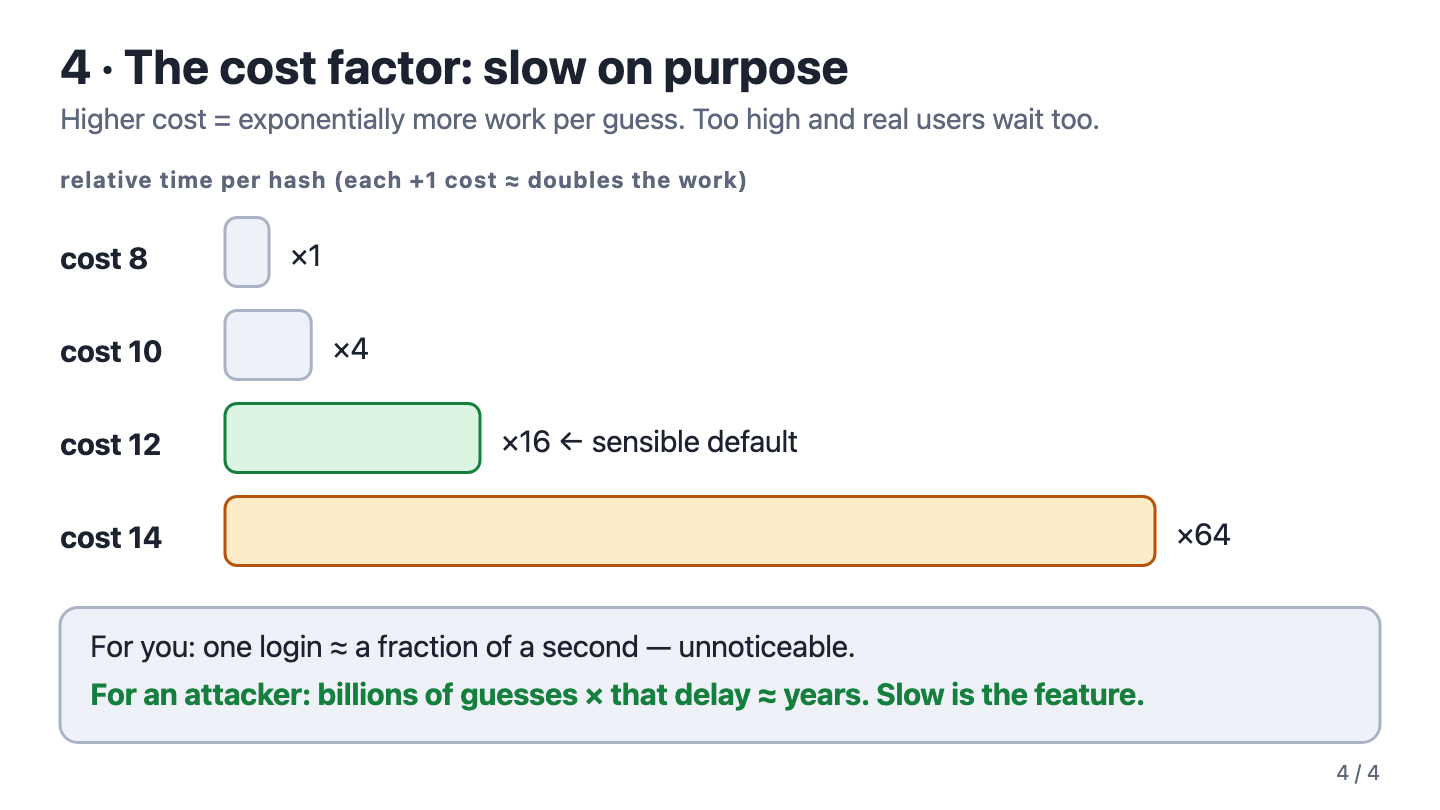

---
## 4. The cost factor — slow is the feature

Each `+1` roughly doubles the work. A fraction of a second for a real login;
days added up across a brute-force attempt.

In [7]:
import time

for rounds in (10, 12, 14):
    start = time.perf_counter()
    bcrypt.hashpw(password_bytes, bcrypt.gensalt(rounds=rounds))
    print(rounds, f"{time.perf_counter() - start:.3f}s")

10 0.040s


12 0.159s


14 0.637s


### Your turn
Time cost factor 8 alongside 10, 12 and 14. How much faster is it?

In [8]:
timings = {}
for cost in (8, 10, 12, 14):
    start = time.perf_counter()
    bcrypt.hashpw(my_password_bytes, bcrypt.gensalt(rounds=cost))
    timings[cost] = time.perf_counter() - start
    print(f"Cost {cost}: {timings[cost]:.4f} seconds")

for cost in (10, 12, 14):
    ratio = timings[cost] / timings[8]
    print(f"Cost {cost} took about {ratio:.1f} times as long as cost 8.")
print("Each +1 doubles the work; expected ratios to cost 8 are about 4, 16 and 64.")
print("These are single-run timings, so background activity can affect the results.")
# Cost 8 is measured for comparison only; the hash functions below use the default cost.


Cost 8: 0.0100 seconds
Cost 10: 0.0399 seconds


Cost 12: 0.1592 seconds


Cost 14: 0.6377 seconds
Cost 10 took about 4.0 times as long as cost 8.
Cost 12 took about 15.9 times as long as cost 8.
Cost 14 took about 63.7 times as long as cost 8.
Each +1 doubles the work; expected ratios to cost 8 are about 4, 16 and 64.
These are single-run timings, so background activity can affect the results.


---
## Topic 2 Challenge

Write `generate_hash(password)` and `is_valid_hash(password, hashed)` — the
two functions this whole week's project rests on. Test both with a right and
a wrong password.

In [9]:
def generate_hash(password):
    """Hash a password and return text that can be saved in a file."""
    password_bytes = password.encode("utf-8")
    return bcrypt.hashpw(password_bytes, bcrypt.gensalt()).decode("utf-8")


def is_valid_hash(password, hashed):
    """Check an entered password against a stored bcrypt hash string."""
    return bcrypt.checkpw(password.encode("utf-8"), hashed.encode("utf-8"))


practice_hash = generate_hash("classroom-sample-26")
print("Stored hash:", practice_hash)
print("Right password:", is_valid_hash("classroom-sample-26", practice_hash))
print("Wrong password:", is_valid_hash("different-sample", practice_hash))
assert isinstance(practice_hash, str)
assert len(practice_hash) == 60
assert is_valid_hash("classroom-sample-26", practice_hash) is True
assert is_valid_hash("different-sample", practice_hash) is False


Stored hash: $2b$12$jTZHKzdCKZBgLynkoPvNF.m6SuPrYyXLav94VYyifXCSSoTaggSdS


Right password: True


Wrong password: False


---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | hashing an account password before storing dataset access credentials |
| **Cyber Security** | verifying a login attempt without ever holding the real password |
| **IT** | hashing service-account credentials in a config management tool |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| passing a `str` instead of `bytes` | `TypeError: argument 'password': 'str' object cannot be converted to 'PyBytes'` | `.encode("utf-8")` first |
| swapping the argument order in `checkpw()` | `ValueError: Invalid salt` | password first, hash second — always |
| storing the salt separately from the hash | unnecessary — and easy to lose track of which belongs to which | bcrypt already embeds it in the hash string |
| picking an unnecessarily high cost factor | logins become slow for everyone, including real users | the default is already a reasonable choice |

## Go deeper

`examples/01_generate_and_check.py` — hashpw, checkpw, the salt embedded in the hash
`examples/02_the_cost_factor.py` — real timings, and what they mean for an attacker
Docs: [bcrypt on PyPI](https://pypi.org/project/bcrypt/)

---
## Recap

| You can now | Using |
|---|---|
| hash a password | `bcrypt.hashpw(password_bytes, bcrypt.gensalt())` |
| verify one | `bcrypt.checkpw(candidate_bytes, hashed)` |
| explain the cost factor | slower per attempt, on purpose |

**Next:** Topic 3 — wiring this into a real register/login flow.